# 05 Room for an ADU

Does a 20 x 30 ft spot fit in the backyard?

**Inputs**
- U-Net v2 (`data/models/unet.pt`, ResNet-34 encoder, 8 flips / turns, tree offset, all from notebook 03) run on NAIP 2022 for the pilot counties, streamed from Planetary Computer
- `data/processed/6950_lots_sf.gpkg` (single-family lots + outlines, from notebook 04)
- `data/raw/6950/naip/` + `labels/` (Cumberland test boxes, for a check against the Chesapeake labels)
- `data/processed/hand_labels.csv` (optional, not made yet)

**Output**
- `data/processed/lots_pilot.csv  (GEOID, lot_id, lon, lat, lot_m2, open_m2, tree_m2, fits, fits_keep_trees, max_fit_sqft, max_fit_keep_trees_sqft)`
- `data/processed/6950_lots_pilot_full.csv` (same lots, extra columns: outline-only rule, tree loss, image coverage, U-Net building area in the yard)
- `data/processed/hand_labels_template.csv` (blank form for hand labels)

Run `python musa6950/get_data.py` and notebooks 03 + 04 first. Use the geoai env.

In [1]:
import os
import sys
import json
import time
import threading
import concurrent.futures as cf
from pathlib import Path

UA = "musa-adu-project (student class project)"
os.environ.update(GDAL_HTTP_USERAGENT=UA, GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MULTIRANGE="YES",
                  GDAL_HTTP_MERGE_CONSECUTIVE_RANGES="YES", GDAL_HTTP_MAX_RETRY="5", GDAL_HTTP_RETRY_DELAY="3",
                  GDAL_HTTP_TIMEOUT="60", GDAL_HTTP_CONNECTTIMEOUT="20")
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely
from rasterio.features import rasterize
from rasterio.windows import Window
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
sys.path.insert(0, str(ROOT / "musa6950"))
from common import RAW, OUT
R6 = RAW / "6950"
FIG = ROOT / "musa6950" / "docs" / "figures"
CACHE = OUT / "6950_lot_stats"          # per NAIP tile results, so a crash can resume. Not committed
CACHE.mkdir(parents=True, exist_ok=True)
UTM = 26918
boxes = gpd.read_file(R6 / "sample_boxes.gpkg")
boxes.groupby(["split", "stratum"]).size()

split  stratum 
test   rural        7
       suburban    10
       urban       10
train  rural       50
       suburban    50
       urban       50
dtype: int64

## Backyard

- Lot minus house minus setbacks (5 ft lot line, 10 ft house)
- Other outlines on the lot (garages, sheds) are taken out with no buffer
- The plan said EPSG:2272 (feet). Here the work is in UTM 18N meters, the NAIP grid, so pixels need no resampling
  - 5 ft = 1.524 m, 10 ft = 3.048 m, 20 x 30 ft = 6.096 x 9.144 m
- "Backyard" = all of the lot left after the setbacks, front or back. Lot rules on front yards differ by town

In [2]:
lots = gpd.read_file(OUT / "6950_lots_sf.gpkg", layer="lots")
bld = gpd.read_file(OUT / "6950_lots_sf.gpkg", layer="buildings")
print(lots.groupby("county").size().to_dict(), len(bld), "outlines")

house = bld[bld["rank"] == 0].set_index("lot_id").geometry
others = bld[bld["rank"] > 0].groupby("lot_id").geometry.apply(lambda g: shapely.union_all(g.values))
h = house.reindex(lots.lot_id).values
o = others.reindex(lots.lot_id).values
inner = shapely.buffer(lots.geometry.values, -1.524)
yard = shapely.difference(inner, shapely.buffer(h, 3.048))
has_o = ~pd.isna(o)
yard[has_o] = shapely.difference(yard[has_o], o[has_o])
lots["yard"] = yard
lots["yard_m2"] = shapely.area(yard)
print("median backyard m2:", lots.groupby("county").yard_m2.median().round(0).to_dict())

{'42041': 57664, '42101': 26270} 96460 outlines


median backyard m2: {'42041': 797.0, '42101': 223.0}


## Fit test

- Open mask -> 20 x 30 ft rectangle (10 x 15 pixels at 0.6 m) must fit fully inside
- Same as binary erosion with the rectangle: done with a summed-area table, which is faster and gives the same answer
- Try both rotations
- `fits` = the rectangle fits on open ground or trees (trees may be cut)
- `fits_keep_trees` = the rectangle fits on open ground only
- Tree loss = when only `fits` is true, the smallest tree area under any spot that fits
- Outline-only rule = the rectangle fits in the backyard shape, no land cover used

Largest footprint that fits (for the tool's size slider):
- Ladder of footprint areas: 100 to 2,000 sq ft in steps of 50
- Each area is tried as 3 shapes: square, 2:3, 1:2. Each shape in both turns
  - Size in pixels = ceil(feet x 0.3048 / 0.6), so the spot is never smaller than asked
- Fits at an area = any of the shapes fits. A bigger area never fits where a smaller one does not, so a binary search on the ladder is enough
- `max_fit_sqft` = largest area that fits (0 = not even 100 sq ft, 2000 = the top of the ladder)
- `max_fit_keep_trees_sqft` = same, tree pixels not allowed
- Same backyard mask as `fits`. Only the shapes differ, so `fits` and `max_fit_sqft >= 600` can disagree on a few lots

In [3]:
from rasterio.features import shapes

PX = 0.6
RW, RH = round(6.096 / PX), round(9.144 / PX)     # 10 x 15 pixels
RECTS = [(RH, RW), (RW, RH)]


def box_sums(m, h, w):
    """Sum of m over every h x w window."""
    if m.shape[0] < h or m.shape[1] < w:
        return None
    c = np.pad(m.astype(np.int32).cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    return c[h:, w:] - c[:-h, w:] - c[h:, :-w] + c[:-h, :-w]


def fits_in(m):
    for h, w in RECTS:
        s = box_sums(m, h, w)
        if s is not None and (s == h * w).any():
            return True
    return False


def min_tree(ok, tree):
    best = None
    for h, w in RECTS:
        s, t = box_sums(ok, h, w), box_sums(tree, h, w)
        if s is None:
            continue
        v = t[s == h * w]
        if v.size:
            best = v.min() if best is None else min(best, v.min())
    return best


LADDER = np.arange(100, 2001, 50)          # sq ft
RATIOS = [1, 1.5, 2]                         # square, 2:3, 1:2


def px(ft):
    return int(np.ceil(ft * 0.3048 / PX - 1e-9))


SHAPES = {}
for a in LADDER:
    s = set()
    for r in RATIOS:
        w = np.sqrt(a / r)
        s |= {(px(w * r), px(w)), (px(w), px(w * r))}
    SHAPES[a] = sorted(s)


def max_fit(m):
    """Largest ladder area (sq ft) whose spot fits fully inside mask m. 0 if none."""
    c = np.pad(m.astype(np.int32).cumsum(0).cumsum(1), ((1, 0), (1, 0)))

    def ok(a):
        for h, w in SHAPES[a]:
            if c.shape[0] > h and c.shape[1] > w:
                if ((c[h:, w:] - c[:-h, w:] - c[h:, :-w] + c[:-h, :-w]) == h * w).any():
                    return True
        return False
    if not m.any() or not ok(LADDER[0]):
        return 0
    lo, hi = 0, len(LADDER) - 1          # ok(LADDER[lo]) is true
    if ok(LADDER[hi]):
        return int(LADDER[hi])
    while hi - lo > 1:
        mid = (lo + hi) // 2
        lo, hi = (mid, hi) if ok(LADDER[mid]) else (lo, mid)
    return int(LADDER[lo])


def place(m, a, house_rc):
    """Spot of area a (sq ft) inside mask m, farthest from the house center. Returns (row, col, h, w) or None."""
    c = np.pad(m.astype(np.int32).cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    best = None
    for h, w in SHAPES[a]:
        if c.shape[0] <= h or c.shape[1] <= w:
            continue
        rr, cc = np.nonzero((c[h:, w:] - c[:-h, w:] - c[h:, :-w] + c[:-h, :-w]) == h * w)
        if not rr.size:
            continue
        d = (rr + h / 2 - house_rc[0]) ** 2 + (cc + w / 2 - house_rc[1]) ** 2 if house_rc is not None else np.zeros(rr.size)
        k = int(d.argmax())
        if best is None or d[k] > best[0]:
            best = (d[k], int(rr[k]), int(cc[k]), h, w)
    return best[1:] if best else None


def vectorize(m, t, tol=0.3, min_m2=4.0):
    """Mask -> one (multi)polygon in UTM, simplified, parts under min_m2 dropped. None if empty."""
    if not m.any():
        return None
    parts = [shapely.geometry.shape(g) for g, v in shapes(m.astype(np.uint8), mask=m, transform=t) if v == 1]
    parts = [q for q in parts if q.area >= min_m2]
    if not parts:
        return None
    g = shapely.union_all(parts).simplify(tol, preserve_topology=True)
    return g if not g.is_empty else None


def lot_stats(cls, transform, lot_geom, yard_geom, house_geom=None, geoms=False):
    """Pixel stats for one lot. cls = class array (0 other, 1 building, 2 tree, 3 open, 255 none)."""
    H, W = cls.shape
    x0, y0, x1, y1 = lot_geom.bounds
    c0, r0 = ~transform * (x0, y1)
    c1, r1 = ~transform * (x1, y0)
    c0, r0 = max(int(np.floor(c0)) - 1, 0), max(int(np.floor(r0)) - 1, 0)
    c1, r1 = min(int(np.ceil(c1)) + 1, W), min(int(np.ceil(r1)) + 1, H)
    if c1 <= c0 or r1 <= r0:
        return None
    win = cls[r0:r1, c0:c1]
    t = transform * rasterio.Affine.translation(c0, r0)
    shp = win.shape
    lm = rasterize([lot_geom], out_shape=shp, transform=t, dtype=np.uint8).astype(bool)
    ym = (rasterize([yard_geom], out_shape=shp, transform=t, dtype=np.uint8).astype(bool)
          if yard_geom is not None and not yard_geom.is_empty else np.zeros(shp, bool))
    n_lot = lm.sum()
    if n_lot == 0:
        return None
    is_open, is_tree = win == 3, win == 2
    ok_keep = ym & is_open
    ok_cut = ym & (is_open | is_tree)
    fk = fits_in(ok_keep)
    f = fk or fits_in(ok_cut)
    loss = 0.0
    if f and not fk:
        loss = float(min_tree(ok_cut, ym & is_tree)) * PX * PX
    out = {"open_m2": float((lm & is_open).sum()) * PX * PX, "tree_m2": float((lm & is_tree).sum()) * PX * PX,
            "yard_open_m2": float(ok_keep.sum()) * PX * PX, "yard_tree_m2": float((ym & is_tree).sum()) * PX * PX,
            "coverage": float((lm & (win != 255)).sum() / n_lot),
            "yard_bldg_m2": float((ym & (win == 1)).sum()) * PX * PX,
            "fits": f, "fits_keep_trees": fk, "tree_loss_m2": loss, "fits_outline": fits_in(ym),
            "max_fit_sqft": max_fit(ok_cut), "max_fit_keep_trees_sqft": max_fit(ok_keep)}
    if geoms:   # polygons for the map: buildable open ground, trees in the setback area, and where the ADU would go
        out["_open"] = vectorize(ok_keep, t)
        out["_tree"] = vectorize(ym & is_tree, t)
        hrc = None
        if house_geom is not None and not house_geom.is_empty:
            cx, cy = house_geom.centroid.x, house_geom.centroid.y
            hc, hr = ~t * (cx, cy)
            hrc = (hr, hc)
        spots = []
        for kind, a in [("max", out["max_fit_sqft"]), ("base600", 600 if out["max_fit_sqft"] >= 600 else 0)]:
            if a == 0:
                continue
            keep = out["max_fit_keep_trees_sqft"] >= a
            p = place(ok_keep if keep else ok_cut, a, hrc)
            if p:
                r, c, h, w = p
                x0, y0 = t * (c, r)
                x1, y1 = t * (c + w, r + h)
                spots.append({"footprint_sqft": int(a), "keeps_trees": bool(keep), "kind": kind,
                              "geometry": shapely.box(min(x0, x1), min(y0, y1), max(x0, x1), max(y0, y1))})
        out["_spots"] = spots
    return out

## Check the rule on lots with real labels

- Cumberland lots that sit fully inside a Cumberland test box have Chesapeake labels (never used in training)
- Run the rule two ways: with the Chesapeake label map, and with the U-Net map
- Agreement tells how much U-Net errors change the answer. It is not a hand-label check

/opt/anaconda3/envs/geoai/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


model: smp resnet34 | NDVI False | TTA True | class offsets [0.0, 0.0, 0.5, 0.0]


3030 Cumberland lots inside test boxes {'rural': 664, 'suburban': 311, 'urban': 2055}


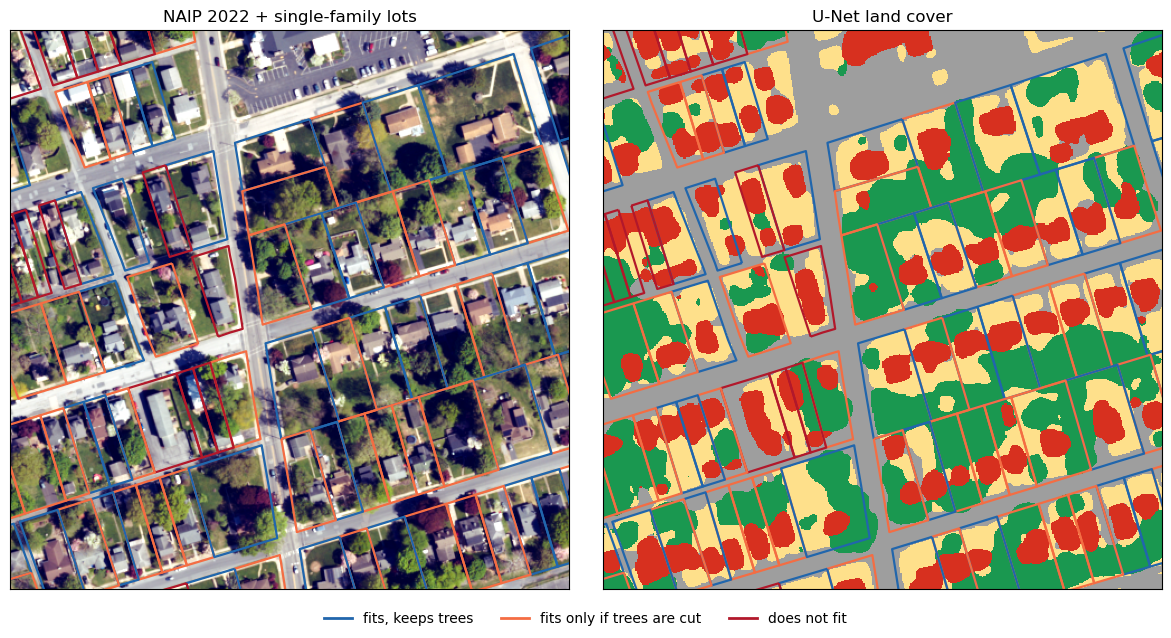

                                       n  share_true_label  share_true_model  precision  recall  agreement
fits (U-Net vs label)             3030.0             0.646             0.641      0.973   0.966      0.961
fits_keep_trees (U-Net vs label)  3030.0             0.419             0.464      0.807   0.895      0.867
fits (outline only vs label)      3030.0             0.646             0.728      0.888   1.000      0.918

open m2 per lot, label vs U-Net: median 287.0 vs 290.0 | correlation 0.96
tree m2 per lot, label vs U-Net: median 159.0 vs 92.0 | correlation 0.94


In [4]:
import torch
from unet import load_model, predict_array, predict_proba, to_input
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
model, meta = load_model(ROOT / "data" / "models" / "unet.pt", device)
mean, std, NDVI, BIAS = meta["mean"], meta["std"], meta["ndvi"], meta["class_bias"]
TTA = True   # from notebook 03: average of flips / turns if it helped on validation
print("model:", meta["kind"], meta.get("encoder", ""), "| NDVI", NDVI, "| TTA", TTA, "| class offsets", BIAS)

rows, show, preds = [], None, {}
for _, b in boxes[(boxes.split == "test") & (boxes.county == "42041")].iterrows():
    p = R6 / "naip" / f"{b.GEOID}.tif"
    if not p.exists():
        continue
    with rasterio.open(p) as s:
        img, tr = s.read(), s.transform
        ext = shapely.box(*s.bounds)
    with rasterio.open(R6 / "labels" / f"{b.GEOID}.tif") as s:
        lab = s.read(1)
    pred = predict_array(model, img, mean, std, device, ndvi=NDVI, tta=TTA, bias=BIAS)
    pred[(img == 0).all(0)] = 255
    inside = lots[(lots.county == "42041") & lots.geometry.within(ext)]
    if show is None or len(inside) > len(show[3]):
        show = (img, pred, tr, inside)
    preds[b.GEOID] = (pred, lab, tr, inside)
    for _, l in inside.iterrows():
        a, u = lot_stats(lab, tr, l.geometry, l.yard), lot_stats(pred, tr, l.geometry, l.yard)
        if a and u:
            rows.append({"lot_id": l.lot_id, "box": b.GEOID, "stratum": b.stratum,
                         **{f"lab_{k}": v for k, v in a.items()}, **{f"unet_{k}": v for k, v in u.items()}})
chk = pd.DataFrame(rows)
print(len(chk), "Cumberland lots inside test boxes", chk.groupby("stratum").size().to_dict())

# picture: the test box with the most lots, 300 m x 300 m around the middle of its lots
img, pred, tr, inside = show
st = chk.set_index("lot_id")
cx, cy = np.median(inside.geometry.centroid.x), np.median(inside.geometry.centroid.y)
c, r = ~tr * (cx, cy)
r0, c0 = int(r) - 250, int(c) - 250
win_tr = tr * rasterio.Affine.translation(c0, r0)
rgb = np.moveaxis(img[:3, r0:r0 + 500, c0:c0 + 500], 0, -1).astype(float)
lo, hi = np.percentile(rgb, [2, 98])
ext_xy = [win_tr.c, win_tr.c + 500 * PX, win_tr.f - 500 * PX, win_tr.f]
from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
axes[0].imshow(np.clip((rgb - lo) / (hi - lo), 0, 1), extent=ext_xy)
axes[1].imshow(np.ma.masked_equal(pred[r0:r0 + 500, c0:c0 + 500], 255), extent=ext_xy, interpolation="nearest",
               cmap=ListedColormap(["#9e9e9e", "#d7301f", "#1a9850", "#fee08b"]), vmin=0, vmax=3)
view = shapely.box(ext_xy[0], ext_xy[2], ext_xy[1], ext_xy[3])
near = inside[inside.geometry.intersects(view) & inside.lot_id.isin(st.index)]
col = {(True, True): "#2166ac", (True, False): "#f46d43", (False, False): "#b2182b"}
for _, l in near.iterrows():
    k = (bool(st.loc[l.lot_id, "unet_fits"]), bool(st.loc[l.lot_id, "unet_fits_keep_trees"]))
    for a in axes:
        gpd.GeoSeries([l.geometry]).boundary.plot(ax=a, color=col[k], linewidth=1.6)
for a in axes:
    a.set_xlim(ext_xy[0], ext_xy[1]); a.set_ylim(ext_xy[2], ext_xy[3]); a.set_xticks([]); a.set_yticks([])
axes[0].set_title("NAIP 2022 + single-family lots"); axes[1].set_title("U-Net land cover")
fig.legend([plt.Line2D([], [], color=v, lw=2) for v in col.values()],
           ["fits, keeps trees", "fits only if trees are cut", "does not fit"], loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig(FIG / "05_lot_example.png", dpi=110, bbox_inches="tight")
plt.show()


def agree(truth, guess):
    tp, fp, fn = (truth & guess).sum(), (~truth & guess).sum(), (truth & ~guess).sum()
    return {"n": int(len(truth)), "share_true_label": round(float(truth.mean()), 3), "share_true_model": round(float(guess.mean()), 3),
            "precision": round(float(tp / max(tp + fp, 1)), 3), "recall": round(float(tp / max(tp + fn, 1)), 3),
            "agreement": round(float((truth == guess).mean()), 3)}


check = {"fits (U-Net vs label)": agree(chk.lab_fits, chk.unet_fits),
         "fits_keep_trees (U-Net vs label)": agree(chk.lab_fits_keep_trees, chk.unet_fits_keep_trees),
         "fits (outline only vs label)": agree(chk.lab_fits, chk.unet_fits_outline)}
check_tab = pd.DataFrame(check).T
print(check_tab.to_string())
print("\nopen m2 per lot, label vs U-Net: median", chk.lab_open_m2.median().round(0), "vs", chk.unet_open_m2.median().round(0),
      "| correlation", round(chk.lab_open_m2.corr(chk.unet_open_m2), 3))
print("tree m2 per lot, label vs U-Net: median", chk.lab_tree_m2.median().round(0), "vs", chk.unet_tree_m2.median().round(0),
      "| correlation", round(chk.lab_tree_m2.corr(chk.unet_tree_m2), 3))

## Small buildings the outlines miss

- The fit test only allows open ground (and trees). So any pixel the U-Net calls building already blocks a spot, outline or not
- How often does that matter? In the Cumberland test boxes, the Chesapeake label has its own building class
- Take each labeled building patch (5-60 m2) inside a lot's backyard (lot minus 5 ft, minus 10 ft around the house). Does a Microsoft outline touch it? Does the U-Net call at least half of it building?
- `yard_bldg_m2` in `6950_lots_pilot_full.csv` = U-Net building area left in the backyard after the outlines are taken out


In [5]:
from scipy import ndimage

bld_all = bld.set_index("lot_id")
rows_s = []
for g, (pred, lab, tr, inside) in preds.items():
    if not len(inside):
        continue
    # backyard before other outlines are taken out: lot minus 5 ft, minus 10 ft around the house
    y0 = shapely.difference(shapely.buffer(inside.geometry.values, -1.524), shapely.buffer(house.reindex(inside.lot_id).values, 3.048))
    yard_m = rasterize([(y, 1) for y in y0 if y is not None and not y.is_empty], out_shape=lab.shape, transform=tr, dtype=np.uint8).astype(bool)
    outl = bld_all[bld_all.index.isin(inside.lot_id)].geometry
    out_m = rasterize([(o, 1) for o in outl], out_shape=lab.shape, transform=tr, dtype=np.uint8).astype(bool) if len(outl) else np.zeros(lab.shape, bool)
    comp, n = ndimage.label((lab == 1) & yard_m)
    if n == 0:
        continue
    idx = np.arange(1, n + 1)
    size = ndimage.sum(np.ones_like(comp), comp, idx) * PX * PX
    hit_outline = ndimage.maximum(out_m, comp, idx) > 0
    unet_share = ndimage.mean(pred == 1, comp, idx)
    rows_s.append(pd.DataFrame({"box": g, "m2": size, "outline": hit_outline, "unet_share": unet_share}))
sh = pd.concat(rows_s)
sh = sh[sh.m2.between(5, 60)]
shed_check = {"label_patches_5_60m2": int(len(sh)), "share_touching_outline": round(float(sh.outline.mean()), 3),
              "share_unet_half_building": round(float((sh.unet_share >= 0.5).mean()), 3),
              "share_missed_by_outline_caught_by_unet": round(float((~sh.outline & (sh.unet_share >= 0.5)).sum() / max((~sh.outline).sum(), 1)), 3),
              "share_missed_by_both": round(float((~sh.outline & (sh.unet_share < 0.5)).mean()), 3),
              "median_m2": round(float(sh.m2.median()), 1)}
print(json.dumps(shed_check, indent=1))


{
 "label_patches_5_60m2": 1143,
 "share_touching_outline": 0.334,
 "share_unet_half_building": 0.355,
 "share_missed_by_outline_caught_by_unet": 0.133,
 "share_missed_by_both": 0.577,
 "median_m2": 18.4
}


## Run the U-Net on the pilot counties

- NAIP 2022 is not saved for whole counties (about 20 GB). Instead:
  - Find the NAIP tiles (quarter quads) that cover the single-family lots
  - Read only the 512 x 512 pixel blocks that touch a lot, plus a 64 px margin, straight from the cloud file (COG)
  - Predict with the U-Net, keep the class map in memory for that tile, compute lot stats, then throw the image away
- A lot goes to the first tile that holds all of it. Lots that no tile holds fully use the tile at their center (`coverage` < 1)
- Results are cached per tile in `data/processed/6950_lot_stats/`, so a stop can resume

In [6]:
import pystac_client
import planetary_computer

cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                modifier=planetary_computer.sign_inplace, headers={"User-Agent": UA})
counties = gpd.read_file(OUT / "counties_2020.gpkg").to_crs(4326)
items = {}
for fips in ["42101", "42041"]:
    geom = counties[counties.GEOID == fips].geometry.iloc[0]
    for it in cat.search(collections=["naip"], intersects=geom.__geo_interface__, datetime="2022").items():
        if it.properties.get("naip:state") == "pa":
            items[it.id] = it
foot = gpd.GeoDataFrame({"item": list(items)}, geometry=[shapely.geometry.shape(it.geometry) for it in items.values()],
                        crs=4326).to_crs(UTM)
print(len(foot), "NAIP 2022 tiles")

env = gpd.GeoDataFrame({"lot_id": lots.lot_id}, geometry=lots.geometry.envelope.buffer(2), crs=UTM)
full = gpd.sjoin(env, foot, predicate="within").drop_duplicates("lot_id")
rest = lots[~lots.lot_id.isin(full.lot_id)]
part = gpd.sjoin(gpd.GeoDataFrame({"lot_id": rest.lot_id}, geometry=rest.geometry.representative_point(), crs=UTM),
                 foot, predicate="within").drop_duplicates("lot_id")
assign = pd.concat([full[["lot_id", "item"]], part[["lot_id", "item"]]]).set_index("lot_id").item
lots["item"] = assign.reindex(lots.lot_id).values
print("lots fully in one tile:", len(full), "| only center in a tile:", len(part), "| no tile:", lots.item.isna().sum())

85 NAIP 2022 tiles


lots fully in one tile: 83934 | only center in a tile: 0 | no tile: 0


In [7]:
B, M = 512, 64
_local = threading.local()


def open_src(href):
    if getattr(_local, "href", None) != href:
        if getattr(_local, "src", None) is not None:
            _local.src.close()
        _local.src, _local.href = rasterio.open(href), href
    return _local.src


def read_block(href, bi, bj):
    s = open_src(href)
    r0, c0 = bi * B - M, bj * B - M
    rr0, cc0 = max(r0, 0), max(c0, 0)
    rr1, cc1 = min(r0 + B + 2 * M, s.height), min(c0 + B + 2 * M, s.width)
    for attempt in range(4):
        try:
            a = s.read([1, 2, 3, 4], window=Window(cc0, rr0, cc1 - cc0, rr1 - rr0))
            break
        except Exception:
            time.sleep(5 * (attempt + 1))
            _local.href = None
            href = planetary_computer.sign(href.split("?")[0])   # fresh token: a long run can outlive the first one
            s = open_src(href)
    else:
        return bi, bj, None
    full = np.pad(a, ((0, 0), (rr0 - r0, r0 + B + 2 * M - rr1), (cc0 - c0, c0 + B + 2 * M - cc1)), mode="reflect")
    nod = np.pad((a == 0).all(0), ((rr0 - r0, r0 + B + 2 * M - rr1), (cc0 - c0, c0 + B + 2 * M - cc1)), constant_values=True)
    return bi, bj, (full, nod)


@torch.no_grad()
def predict_blocks(blocks):
    x = to_input(torch.from_numpy(np.stack([b[0] for b in blocks])).to(device), mean, std, NDVI)
    p = predict_proba(model, x, TTA, BIAS).argmax(1).cpu().numpy().astype(np.uint8)
    p[np.stack([b[1] for b in blocks])] = 255
    return p[:, M:M + B, M:M + B]


def run_item(item_id, sub):
    href = planetary_computer.sign(items[item_id].assets["image"].href.split("?")[0])   # fresh token per tile
    with rasterio.open(href) as s:
        H, W, tr = s.height, s.width, s.transform
    inv = ~tr
    need = set()
    for g in sub.geometry:
        x0, y0, x1, y1 = g.bounds
        c0, r0 = inv * (x0, y1)
        c1, r1 = inv * (x1, y0)
        for bi in range(max(int(r0) // B, 0), min(int(r1) // B, (H - 1) // B) + 1):
            for bj in range(max(int(c0) // B, 0), min(int(c1) // B, (W - 1) // B) + 1):
                need.add((bi, bj))
    cls = np.full((-(-H // B) * B, -(-W // B) * B), 255, np.uint8)
    batch, failed = [], 0
    with cf.ThreadPoolExecutor(24) as ex:
        for bi, bj, blk in ex.map(lambda k: read_block(href, *k), sorted(need)):
            if blk is None:
                failed += 1
                continue
            batch.append((bi, bj, blk))
            if len(batch) == 8:
                for (i, j, _), p in zip(batch, predict_blocks([b[2] for b in batch])):
                    cls[i * B:(i + 1) * B, j * B:(j + 1) * B] = p
                batch = []
        if batch:
            for (i, j, _), p in zip(batch, predict_blocks([b[2] for b in batch])):
                cls[i * B:(i + 1) * B, j * B:(j + 1) * B] = p
    cls = cls[:H, :W]
    out, geo = [], []
    for _, l in sub.iterrows():
        r = lot_stats(cls, tr, l.geometry, l.yard, house.get(l.lot_id), geoms=True)
        if r:
            for k in ["open", "tree"]:
                g = r.pop(f"_{k}")
                if g is not None:
                    geo.append({"lot_id": l.lot_id, "layer": "open", "cls": k, "area_sqft": round(g.area / 0.09290304), "geometry": g})
            for sp in r.pop("_spots"):
                geo.append({"lot_id": l.lot_id, "layer": "spot", **sp})
            out.append({"lot_id": l.lot_id, **r})
    return pd.DataFrame(out), gpd.GeoDataFrame(geo, geometry="geometry", crs=UTM) if geo else None, len(need), failed

In [8]:
SAMPLE = None   # None = every single-family lot. Set a number to run a random sample (seed 42) if this is too slow
todo = lots.dropna(subset=["item"])
if SAMPLE:
    todo = todo.sample(SAMPLE, random_state=42)
log_path = CACHE / "progress.log"
t0, n_blocks = time.time(), 0
for k, (item_id, sub) in enumerate(todo.groupby("item")):
    dest = CACHE / f"{item_id}.csv"
    if dest.exists():
        continue
    t1 = time.time()
    res, geo, nb, failed = run_item(item_id, sub)
    if geo is not None:
        geo.to_pickle(CACHE / f"{item_id}_geom.pkl")
    res.to_csv(dest, index=False)
    n_blocks += nb
    msg = (f"[{k + 1}/{todo.item.nunique()}] {item_id}: {len(sub)} lots, {nb} blocks, {failed} failed, "
           f"{time.time() - t1:.0f} s, total {(time.time() - t0) / 60:.1f} min")
    with open(log_path, "a") as f:
        f.write(msg + "\n")
    print(msg)
print(f"done: {n_blocks} blocks read this run, {(time.time() - t0) / 60:.1f} min")

[49/74] pa_m_4007754_sw_18_060_20220428: 516 lots, 210 blocks, 0 failed, 84 s, total 1.4 min


[50/74] pa_m_4007755_ne_18_060_20220510: 2944 lots, 253 blocks, 0 failed, 102 s, total 3.1 min


[51/74] pa_m_4007755_nw_18_060_20220424: 3336 lots, 281 blocks, 0 failed, 117 s, total 5.1 min


[52/74] pa_m_4007755_se_18_060_20220510: 2414 lots, 246 blocks, 0 failed, 95 s, total 6.6 min


[53/74] pa_m_4007755_sw_18_060_20220424: 1166 lots, 193 blocks, 0 failed, 82 s, total 8.0 min


[54/74] pa_m_4007756_ne_18_060_20220510: 5675 lots, 317 blocks, 0 failed, 121 s, total 10.0 min


... (16 outputs left out)

[71/74] pa_m_4007763_se_18_060_20220510: 150 lots, 57 blocks, 0 failed, 29 s, total 24.9 min


[72/74] pa_m_4007763_sw_18_060_20220424: 258 lots, 84 blocks, 0 failed, 44 s, total 25.7 min


[73/74] pa_m_4007764_ne_18_060_20220510: 4 lots, 2 blocks, 0 failed, 4 s, total 25.7 min


[74/74] pa_m_4007764_nw_18_060_20220629: 69 lots, 22 blocks, 0 failed, 19 s, total 26.0 min
done: 3728 blocks read this run, 26.0 min


In [9]:
stats = pd.concat([pd.read_csv(f) for f in CACHE.glob("*.csv")], ignore_index=True).drop_duplicates("lot_id")
pilot = lots.drop(columns=["yard", "item"]).merge(stats, on="lot_id", how="inner")
print(len(pilot), "lots with stats of", len(lots))
print("image coverage < 0.9:", (pilot.coverage < 0.9).sum())
pilot = pilot[pilot.coverage >= 0.9]
pilot["county_name"] = pilot.county.map({"42101": "Philadelphia", "42041": "Cumberland"})
summary = pilot.groupby("county_name").agg(lots=("lot_id", "size"), fits=("fits", "mean"),
                                           fits_keep_trees=("fits_keep_trees", "mean"), fits_outline_only=("fits_outline", "mean"),
                                           median_lot_m2=("lot_m2", "median"), median_open_m2=("open_m2", "median"),
                                           median_tree_m2=("tree_m2", "median"))
print(summary.round(3).to_string())

# size ladder: does max_fit_sqft >= 600 agree with the 20 x 30 ft rule?
same = pilot.fits.astype(bool) == (pilot.max_fit_sqft >= 600)
same_k = pilot.fits_keep_trees.astype(bool) == (pilot.max_fit_keep_trees_sqft >= 600)
ladder_check = {"fits_vs_max_fit_600": round(float(same.mean()), 4), "keep_vs_max_fit_keep_600": round(float(same_k.mean()), 4),
                "old_yes_new_no": int((pilot.fits.astype(bool) & (pilot.max_fit_sqft < 600)).sum()),
                "old_no_new_yes": int((~pilot.fits.astype(bool) & (pilot.max_fit_sqft >= 600)).sum())}
print("\nsize ladder check:", ladder_check)
assert (pilot.max_fit_keep_trees_sqft <= pilot.max_fit_sqft).all()
print(pilot.groupby("county_name")[["max_fit_sqft", "max_fit_keep_trees_sqft"]].median())

83934 lots with stats of 83934
image coverage < 0.9: 0
               lots   fits  fits_keep_trees  fits_outline_only  median_lot_m2  median_open_m2  median_tree_m2
county_name                                                                                                  
Cumberland    57664  0.872            0.695              0.906       1425.387          599.76          288.72
Philadelphia  26270  0.487            0.223              0.574        637.213          185.76          109.80

size ladder check: {'fits_vs_max_fit_600': 0.9818, 'keep_vs_max_fit_keep_600': 0.9785, 'old_yes_new_no': 1283, 'old_no_new_yes': 244}
              max_fit_sqft  max_fit_keep_trees_sqft
county_name                                        
Cumberland          2000.0                   1100.0
Philadelphia         500.0                    200.0


## Check against hand labels

- Precision, recall
- Outline-only rule vs U-Net rule
- **Needs `data/processed/hand_labels.csv`. Not made yet (see notebook 01).** The blank form is saved below

In [10]:
form = pilot.sample(min(250, len(pilot)), random_state=42)
pt = gpd.GeoSeries(form.geometry.representative_point(), crs=UTM).to_crs(4326)
pd.DataFrame({"lot_id": form.lot_id, "county": form.county_name, "lon": pt.x.round(6), "lat": pt.y.round(6),
              "fits": "", "fits_keep_trees": ""}).to_csv(OUT / "hand_labels_template.csv", index=False)
hl_path = OUT / "hand_labels.csv"
if hl_path.exists():
    hl = pd.read_csv(hl_path).dropna(subset=["fits"]).merge(pilot, on="lot_id", suffixes=("_hand", ""))
    tb = lambda s: s.astype(str).str.lower().isin(["true", "1", "yes"])
    hand = pd.DataFrame({"fits (U-Net)": agree(tb(hl.fits_hand), hl.fits.astype(bool)),
                         "fits_keep_trees (U-Net)": agree(tb(hl.fits_keep_trees_hand), hl.fits_keep_trees.astype(bool)),
                         "fits (outline only)": agree(tb(hl.fits_hand), hl.fits_outline.astype(bool))}).T
    print(hand.to_string())
else:
    print("No hand labels yet. Blank form saved to", (OUT / "hand_labels_template.csv").relative_to(ROOT))

No hand labels yet. Blank form saved to data/processed/hand_labels_template.csv


## Outline-only rule vs U-Net rule

fits                           U-Net fits  U-Net no
row_0                                              
Cumberland outline-only no              0      5418
Cumberland outline-only yes         50287      1959
Philadelphia outline-only no            0     11188
Philadelphia outline-only yes       12790      2292


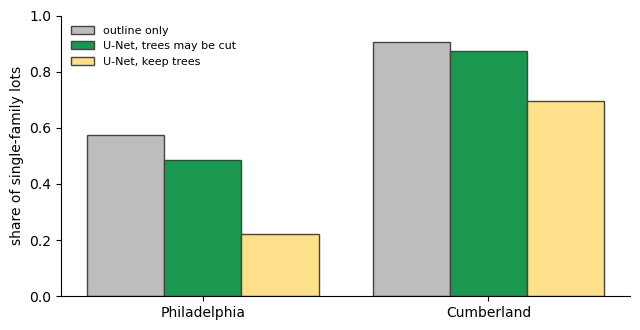

In [11]:
cmp = pd.crosstab(pilot.county_name + " outline-only " + pilot.fits_outline.map({True: "yes", False: "no"}),
                  pilot.fits.map({True: "U-Net fits", False: "U-Net no"}))
print(cmp.to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(2)
cols = [("fits_outline", "outline only", "#bdbdbd"), ("fits", "U-Net, trees may be cut", "#1a9850"),
        ("fits_keep_trees", "U-Net, keep trees", "#fee08b")]
for k, (c, lab, colr) in enumerate(cols):
    ax.bar(x + (k - 1) * 0.27, [summary.loc[n, {"fits_outline": "fits_outline_only"}.get(c, c)] for n in ["Philadelphia", "Cumberland"]],
           0.27, label=lab, color=colr, edgecolor="#444")
ax.set_xticks(x, ["Philadelphia", "Cumberland"]); ax.set_ylabel("share of single-family lots")
ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "05_fit_rates.png", dpi=110)
plt.show()

## Save

- `lots_pilot.csv` has the columns the tool reads. No owner names
- lon / lat = a point inside the lot (representative point)
- `open_m2`, `tree_m2` = whole lot. The fit test only uses the backyard part
- `max_fit_sqft`, `max_fit_keep_trees_sqft` = largest footprint on the ladder that fits

In [12]:
pt = gpd.GeoSeries(pilot.geometry.representative_point(), crs=UTM).to_crs(4326)
pilot["lon"], pilot["lat"] = pt.x.round(6).values, pt.y.round(6).values
out = pilot[["GEOID", "lot_id", "lon", "lat", "lot_m2", "open_m2", "tree_m2", "fits", "fits_keep_trees",
             "max_fit_sqft", "max_fit_keep_trees_sqft"]].copy()
out[["lot_m2", "open_m2", "tree_m2"]] = out[["lot_m2", "open_m2", "tree_m2"]].round(1)
out["fits"] = out.fits.map({True: "true", False: "false"})
out["fits_keep_trees"] = out.fits_keep_trees.map({True: "true", False: "false"})
out.to_csv(OUT / "lots_pilot.csv", index=False)
extra = pilot.drop(columns="geometry")
extra.to_csv(OUT / "6950_lots_pilot_full.csv", index=False)
json.dump({"check_vs_chesapeake": check, "n_check_lots": int(len(chk)), "summary": summary.round(4).reset_index().to_dict("records"),
           "n_lots_selected": int(len(lots)), "n_lots_out": int(len(out)),
           "size_ladder_check": ladder_check, "shed_check": shed_check, "model": meta.get("tag", meta["kind"]), "tta": TTA},
          open(OUT / "6950_metrics_rule.json", "w"), indent=1)
print(len(out), "rows saved to lots_pilot.csv")
out.head()

83934 rows saved to lots_pilot.csv


,GEOID,lot_id,lon,lat,lot_m2,open_m2,tree_m2,fits,fits_keep_trees,max_fit_sqft,max_fit_keep_trees_sqft
0,42101027000,42101-4,-75.137588,40.050422,452.5,148.7,148.7,true,false,900,150
1,42101020800,42101-18,-75.197937,40.016087,2059.7,611.6,1103.8,true,true,2000,1700
2,42101033800,42101-49,-75.078173,40.062416,332.4,116.6,9.7,false,false,350,300
3,42101035100,42101-52,-74.989732,40.044622,718.7,443.2,0.0,true,true,650,650
4,42101030100,42101-61,-75.088371,40.018393,489.3,22.3,216.4,false,false,300,0


## Map layers: where the room is, and where the ADU would go

- `6950_lot_open.gpkg` (layer `open`): per lot, `open` = buildable open ground after setbacks, `tree` = trees inside the setback area (room only if trees are cut)
  - Pixel outlines, simplified 0.3 m, bits under 4 m2 dropped. EPSG:4326
- `6950_lot_spot.gpkg` (layer `spot`): the rectangle the fit test found
  - `kind = max`: at the lot's `max_fit_sqft`. `kind = base600`: at 600 sq ft, if it fits
  - `keeps_trees = true` if the spot fits on open ground alone, then it is placed there. Else on open ground + trees
  - Of all spots that fit, the one whose center is farthest from the house center is kept (more likely the backyard)
  - Squares on the pixel grid (UTM 18N), so a little turned in lon / lat


In [13]:
geo = pd.concat([pd.read_pickle(f) for f in sorted(CACHE.glob("*_geom.pkl"))], ignore_index=True)
geo = gpd.GeoDataFrame(geo, geometry="geometry", crs=UTM)
geo = geo[geo.lot_id.isin(out.lot_id)]
lot_open = geo[geo.layer == "open"][["lot_id", "cls", "area_sqft", "geometry"]].to_crs(4326)
lot_spot = geo[geo.layer == "spot"][["lot_id", "footprint_sqft", "keeps_trees", "kind", "geometry"]].to_crs(4326)
lot_spot["keeps_trees"] = lot_spot.keeps_trees.astype(bool)
for f in ["6950_lot_open.gpkg", "6950_lot_spot.gpkg"]:
    (OUT / f).unlink(missing_ok=True)
lot_open.to_file(OUT / "6950_lot_open.gpkg", layer="open")
lot_spot.to_file(OUT / "6950_lot_spot.gpkg", layer="spot")
print(lot_open.groupby("cls").size().to_dict(), "| spots:", lot_spot.groupby("kind").size().to_dict())
# check: spot counts match the table
assert (lot_spot.kind == "max").sum() == (out.max_fit_sqft > 0).sum()
assert (lot_spot.kind == "base600").sum() == (out.max_fit_sqft >= 600).sum()
for f in ["6950_lot_open.gpkg", "6950_lot_spot.gpkg"]:
    print(f, f"{(OUT / f).stat().st_size / 1e6:.1f} MB")


{'open': 77513, 'tree': 65997} | spots: {'base600': 62038, 'max': 79348}
6950_lot_open.gpkg 430.3 MB
6950_lot_spot.gpkg 32.9 MB
